### Langkah 0 - Persiapan
Instalasi library `pandas`, `numpy`, `matplotlib`, dan `scikit-learn`.

In [1]:
!pip install -q pandas numpy matplotlib scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

### Langkah 1 - Memuat Data
Dataset yang digunakan adalah `Iris.csv`.

In [3]:
df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Langkah 2 - Seleksi Fitur
Fitur yang dipakai untuk clustering adalah keempat kolom numerik (`SepalLengthCm` s.d. `PetalWidthCm`).

In [4]:
# Seleksi Fitur
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Langkah 3 - Visualisasi Data
Karena data berdimensi 4, kita plot sebaran berdasarkan `SepalLengthCm` dan `SepalWidthCm` saja.

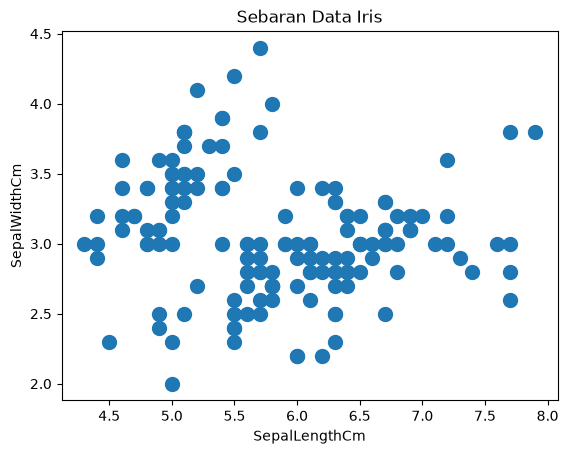

In [5]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width saja
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.title('Sebaran Data Iris')
plt.show()

### Langkah 4 - Membuat Model KMeans
Kali ini kita coba menggunakan k=2, anggap saja kita tidak tahu jumlah label sebenarnya ada 3.

In [6]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

### Langkah 5 - Visualisasi Hasil Klaster

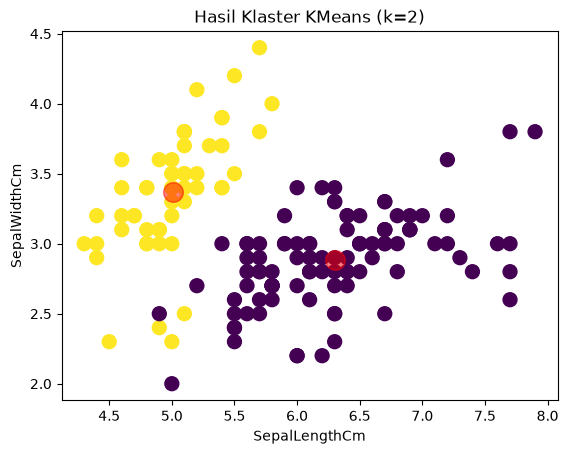

In [7]:
# Plot hasil cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.title('Hasil Klaster KMeans (k=2)')
plt.show()

### Langkah 6 - Mengecek Nilai SSE

In [8]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.3479517603579


### Langkah 7 - Metode Elbow
Mencari jumlah klaster (`k`) terbaik dengan melihat titik "siku" pada grafik SSE.

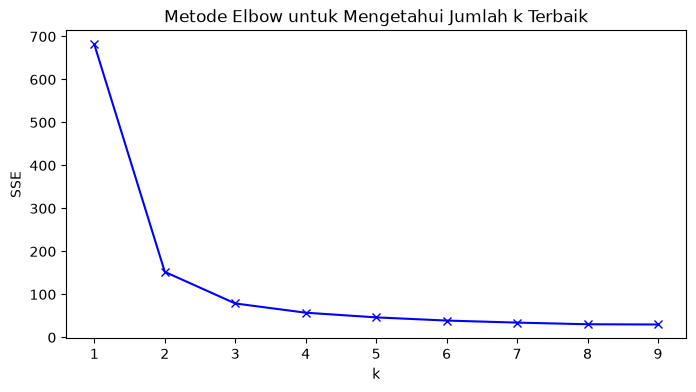

In [9]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1, 10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [10]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=681.3706
k=2; SSE=152.3479517603579
k=3; SSE=78.8556658259773
k=4; SSE=57.35088021295475
k=5; SSE=46.472230158730156
k=6; SSE=39.066035353535355
k=7; SSE=34.30581529581531
k=8; SSE=30.476222943722952
k=9; SSE=29.90624665913797


### Kesimpulan
Nilai SSE turun tajam hingga `k=3` lalu melandai, sehingga `k=3` merupakan jumlah klaster terbaik. Hal ini sesuai dengan jumlah spesies pada dataset Iris (setosa, versicolor, virginica).